# 03 — Búsqueda guiada: evidencia histórica y estimaciones

La búsqueda A/B es una aplicación secundaria exploratoria, separada del benchmark principal por regresor. A proyecta propuestas a diseños históricos y obtiene respuestas registradas después de actuar. B consulta un sustituto congelado para configuraciones nuevas: esas respuestas son estimaciones pendientes de FEM.

In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = {"png", "svg"}
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from truss_research.evaluacion.presentacion import notebook_context

context = notebook_context()
CONFIG = context.config
STUDY_DIR, REPORT_DIR = context.study_dir, context.report_dir
DATA_DIR = CONFIG.data_dir
display(
    Markdown(
        f"**Estudio:** `{STUDY_DIR.name}` — **etiqueta:** `{CONFIG.label}` — **informe:** `{REPORT_DIR.name}`"
    )
)
if CONFIG.label == "comprobacion":
    display(
        Markdown(
            "**Comprobación técnica: sus métricas no constituyen resultados de tesis.**"
        )
    )

**Estudio:** `comparacion_tres_objetivos_final_002` — **etiqueta:** `posterior` — **informe:** `informe_001`

## 1. Estrategias, aprendizaje y presupuestos comunes

La configuración y las tablas definen estrategias, población inicial, escenarios y presupuestos efectivos. La población inicial consume presupuesto. No se infiere un historial de padres u operadores del archivo original.

Las políticas se entrenan en mundos predictivos derivados de ajuste. Su checkpoint se elige por AUC predicho en otro mundo definido con esos modelos, sin actualizar gradientes durante esa evaluación. Esta validación interna de políticas no usa respuestas históricas como si fueran nuevas mediciones. A continuación, las políticas congeladas se comparan en A y B. La fase de prueba del protocolo actual se ejecuta después de congelar decisiones, conservando la advertencia de que el archivo ya había sido examinado.

Evolución genética, evolución diferencial, aleatorio, greedy, Double DQN y bandit contextual tienen roles distintos. El bandit comparte estado y capacidad, pero aprende recompensa inmediata; contrasta el aporte del valor futuro en esta implementación. Las variantes asistidas consultan otro predictor y contabilizan ese costo.

In [2]:
display(
    pd.Series(
        {
            "estrategias": CONFIG.search.strategies,
            "presupuestos": CONFIG.budgets,
            "población_inicial": CONFIG.evolution.population_size,
            "propuestas_por_lote": CONFIG.proposals.pool_size,
            "semillas": CONFIG.seeds,
            "escenarios_pareados": CONFIG.proposals.evaluation_episodes,
            "interacciones_por_política": CONFIG.rl_steps,
        }
    )
)
comparison = pd.read_csv(REPORT_DIR / "comparison.csv")
display(comparison)

estrategias                   (evolution, random, greedy, rl, rl_assisted, c...
presupuestos                                                       (32, 64, 96)
población_inicial                                                             8
propuestas_por_lote                                                          32
semillas                                                   (42, 43, 44, 45, 46)
escenarios_pareados                                                          20
interacciones_por_política                                                50000
dtype: object

,split,experiment,strategy,budget,mean_auc,mean_hypervolume,attainment_rate,mean_seconds,mean_evaluations,mean_generated,...,mean_duplicates,mean_unsupported_queries,mean_projection_distance,mean_cheap_predictions,mean_generation_seconds,mean_selection_seconds,mean_evaluation_seconds,mean_cheap_seconds,mean_design_distance,mean_topology_count
0,test,A,contextual_bandit,32,0.686238,0.070953,0.00,0.251641,32.0,768.0,...,18.51,0.60,0.038521,0.00,0.123649,0.072657,0.002025,0.000000,0.325475,2.65
1,test,A,contextual_bandit,64,0.741986,0.072941,0.00,0.598055,64.0,1792.0,...,53.80,0.72,0.035181,0.00,0.295970,0.175739,0.004704,0.000000,0.313318,2.65
2,test,A,contextual_bandit,96,0.767118,0.074396,0.01,0.948053,96.0,2816.0,...,90.93,1.27,0.034157,0.00,0.468746,0.277699,0.007381,0.000000,0.305462,2.65
3,test,A,contextual_bandit_assisted,32,0.685762,0.071135,0.00,0.312785,32.0,768.0,...,18.53,0.45,0.037651,730.68,0.123896,0.066735,0.001977,0.065506,0.321173,2.65
4,test,A,contextual_bandit_assisted,64,0.743833,0.073976,0.00,0.747083,64.0,1792.0,...,51.43,0.99,0.035294,1711.78,0.296040,0.163926,0.004680,0.156697,0.311580,2.65
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,validation,B,rl,64,0.653795,0.064539,0.00,1.461243,64.0,1792.0,...,5.30,0.00,0.000000,0.00,0.291139,0.199858,0.829718,0.000000,0.245817,3.39
104,validation,B,rl,96,0.678210,0.066465,0.00,2.344275,96.0,2816.0,...,7.84,0.00,0.000000,0.00,0.464501,0.357831,1.300707,0.000000,0.248417,3.60
105,validation,B,rl_assisted,32,0.610926,0.062217,0.00,0.682904,32.0,768.0,...,2.19,0.00,0.000000,709.14,0.125394,0.070390,0.356347,0.067526,0.316232,3.67
106,validation,B,rl_assisted,64,0.656287,0.065055,0.00,1.614512,64.0,1792.0,...,4.59,0.00,0.000000,1665.62,0.302001,0.185639,0.826808,0.155717,0.287738,3.90


## 2. A: recuperación retrospectiva

Las respuestas de A corresponden a los diseños registrados a los que se proyectan las propuestas. Las distancias y consultas sin topología compatible delimitan la interpretación. Una consulta sin soporte consume presupuesto. Menos consultas en este banco no prueban ahorro FEM.

Se comparan estrategias dentro del mismo experimento, partición y presupuesto. El resultado no valida la geometría propuesta antes de proyectarla.

,split,experiment,strategy,budget,mean_auc,mean_hypervolume,attainment_rate,mean_seconds,mean_evaluations,mean_generated,...,mean_duplicates,mean_unsupported_queries,mean_projection_distance,mean_cheap_predictions,mean_generation_seconds,mean_selection_seconds,mean_evaluation_seconds,mean_cheap_seconds,mean_design_distance,mean_topology_count
0,test,A,contextual_bandit,32,0.686238,0.070953,0.00,0.251641,32.0,768.00,...,18.51,0.60,0.038521,0.00,0.123649,0.072657,0.002025,0.000000,0.325475,2.65
1,test,A,contextual_bandit,64,0.741986,0.072941,0.00,0.598055,64.0,1792.00,...,53.80,0.72,0.035181,0.00,0.295970,0.175739,0.004704,0.000000,0.313318,2.65
2,test,A,contextual_bandit,96,0.767118,0.074396,0.01,0.948053,96.0,2816.00,...,90.93,1.27,0.034157,0.00,0.468746,0.277699,0.007381,0.000000,0.305462,2.65
3,test,A,contextual_bandit_assisted,32,0.685762,0.071135,0.00,0.312785,32.0,768.00,...,18.53,0.45,0.037651,730.68,0.123896,0.066735,0.001977,0.065506,0.321173,2.65
4,test,A,contextual_bandit_assisted,64,0.743833,0.073976,0.00,0.747083,64.0,1792.00,...,51.43,0.99,0.035294,1711.78,0.296040,0.163926,0.004680,0.156697,0.311580,2.65
5,test,A,contextual_bandit_assisted,96,0.767892,0.075106,0.00,1.176716,96.0,2816.00,...,89.35,1.47,0.034525,2689.28,0.466885,0.259424,0.007302,0.243918,0.308715,2.65
6,test,A,de,32,0.685460,0.071824,0.00,0.024010,32.0,27.10,...,6.85,1.65,0.055084,0.00,0.006988,0.000103,0.001311,0.000000,0.308705,2.65
7,test,A,de,64,0.751348,0.075308,0.00,0.050085,64.0,62.45,...,25.70,3.60,0.051070,0.00,0.016519,0.000278,0.002993,0.000000,0.304291,2.65
8,test,A,de,96,0.783611,0.077643,0.15,0.072177,96.0,98.05,...,47.90,5.95,0.050213,0.00,0.025341,0.000396,0.004712,0.000000,0.303352,2.65
9,test,A,de_assisted,32,0.682090,0.070522,0.00,0.273594,32.0,768.00,...,25.35,1.35,0.045696,695.10,0.079078,0.072961,0.001723,0.067433,0.322001,2.65


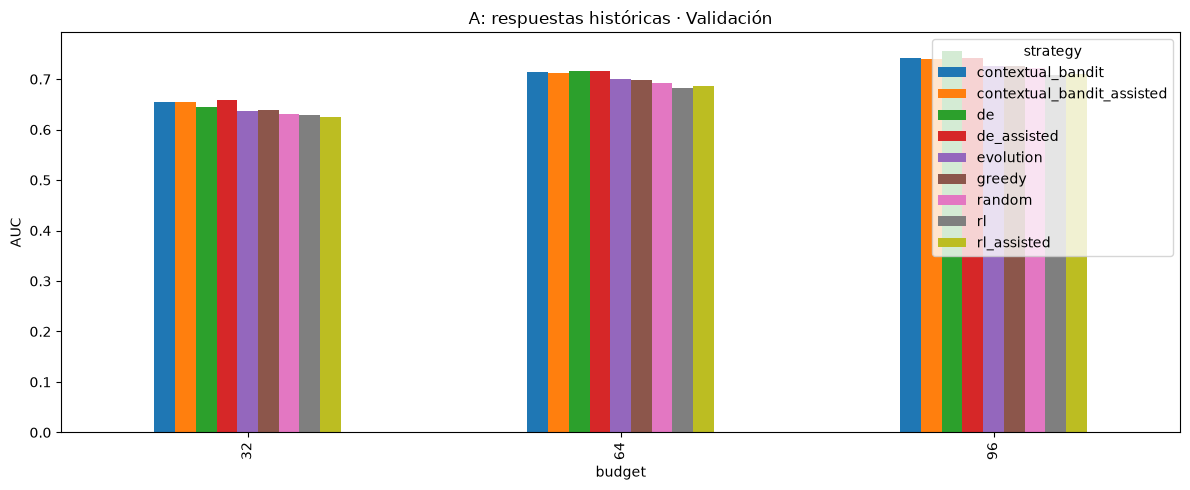

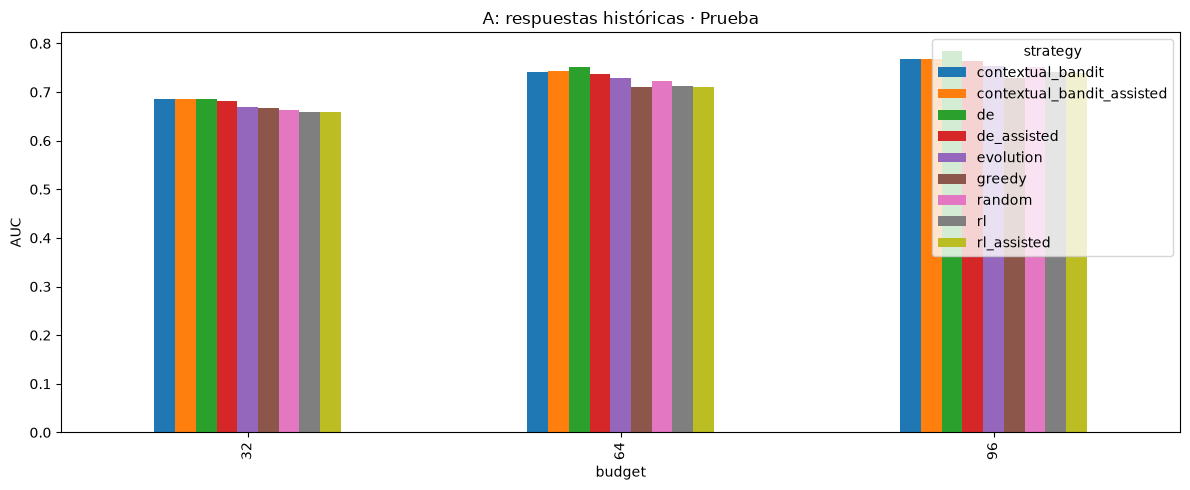

,experiment,budget,strategy,baseline,mean_auc_difference,lower,upper,training_seed_pairs,scenario_pairs,scope
0,A,32,rl,contextual_bandit,-0.026647,-0.041818,-0.009838,5,20,exploratory_crossed_seeds_scenarios_single_his...
1,A,32,rl_assisted,contextual_bandit_assisted,-0.027482,-0.042139,-0.014011,5,20,exploratory_crossed_seeds_scenarios_single_his...
2,A,32,contextual_bandit,random,0.023902,0.009152,0.040703,5,20,exploratory_crossed_seeds_scenarios_single_his...
3,A,32,rl,random,-0.002745,-0.017035,0.012175,5,20,exploratory_crossed_seeds_scenarios_single_his...
4,A,32,contextual_bandit_assisted,greedy,0.018212,0.007746,0.028871,5,20,exploratory_crossed_seeds_scenarios_single_his...
5,A,32,rl_assisted,greedy,-0.009270,-0.022534,0.003348,5,20,exploratory_crossed_seeds_scenarios_single_his...
6,A,32,de,evolution,0.016520,0.001523,0.032086,1,20,exploratory_crossed_seeds_scenarios_single_his...
7,A,32,de_assisted,greedy,0.014541,0.003927,0.026487,1,20,exploratory_crossed_seeds_scenarios_single_his...
8,A,64,rl,contextual_bandit,-0.028742,-0.046645,-0.009917,5,20,exploratory_crossed_seeds_scenarios_single_his...
9,A,64,rl_assisted,contextual_bandit_assisted,-0.032731,-0.054987,-0.015108,5,20,exploratory_crossed_seeds_scenarios_single_his...


In [3]:
historical = comparison.loc[comparison["experiment"].eq("A")]
display(historical)
for split, label in (("validation", "Validación"), ("test", "Prueba")):
    historical.loc[historical["split"].eq(split)].pivot(
        index="budget", columns="strategy", values="mean_auc"
    ).plot.bar(
        figsize=(12, 5), ylabel="AUC", title=f"A: respuestas históricas · {label}"
    )
    plt.tight_layout()
    plt.show()

display(pd.read_csv(STUDY_DIR / "evolution/test/paired_intervals.csv"))

## 3. B: generación evaluada por un sustituto

B usa respuestas predictivas y soporte definido con ajuste. Acuerdo entre miembros del evaluador no constituye incertidumbre física calibrada. Su HV/AUC describe calidad estimada, no respuestas FEM nuevas; las magnitudes de A y B no se interpretan como evidencia intercambiable.

,split,experiment,strategy,budget,mean_auc,mean_hypervolume,attainment_rate,mean_seconds,mean_evaluations,mean_generated,...,mean_duplicates,mean_unsupported_queries,mean_projection_distance,mean_cheap_predictions,mean_generation_seconds,mean_selection_seconds,mean_evaluation_seconds,mean_cheap_seconds,mean_design_distance,mean_topology_count
27,test,B,contextual_bandit,32,0.676759,0.069433,0.0,0.626721,32.0,768.00,...,2.41,0.0,0.0,0.00,0.125870,0.078171,0.358859,0.000000,0.266357,2.88
28,test,B,contextual_bandit,64,0.729528,0.071672,0.0,1.513931,64.0,1792.00,...,6.20,0.0,0.0,0.00,0.301732,0.213737,0.850957,0.000000,0.238635,3.04
29,test,B,contextual_bandit,96,0.752892,0.072889,0.0,2.500700,96.0,2816.00,...,10.05,0.0,0.0,0.00,0.497643,0.400947,1.366285,0.000000,0.229477,3.22
30,test,B,contextual_bandit_assisted,32,0.676940,0.069486,0.0,0.699980,32.0,768.00,...,1.98,0.0,0.0,732.27,0.133159,0.072510,0.360002,0.068716,0.271343,2.90
31,test,B,contextual_bandit_assisted,64,0.731268,0.071881,0.0,1.664320,64.0,1792.00,...,5.74,0.0,0.0,1699.74,0.302193,0.198914,0.850284,0.162755,0.251265,3.07
32,test,B,contextual_bandit_assisted,96,0.755684,0.073403,0.0,2.743055,96.0,2816.00,...,9.28,0.0,0.0,2655.71,0.493755,0.377366,1.369043,0.261670,0.246267,3.20
33,test,B,de,32,0.658639,0.068312,0.0,0.379777,32.0,28.00,...,0.05,0.0,0.0,0.00,0.008138,0.000127,0.350253,0.000000,0.333306,3.70
34,test,B,de,64,0.720170,0.072490,0.0,0.894781,64.0,63.60,...,0.35,0.0,0.0,0.00,0.019139,0.000319,0.827227,0.000000,0.322367,4.50
35,test,B,de,96,0.751017,0.074182,0.0,1.444285,96.0,99.30,...,0.85,0.0,0.0,0.00,0.030917,0.000502,1.335545,0.000000,0.322395,4.75
36,test,B,de_assisted,32,0.688939,0.071498,0.0,0.643440,32.0,768.00,...,14.95,0.0,0.0,682.70,0.079993,0.074447,0.359299,0.068723,0.288183,3.15


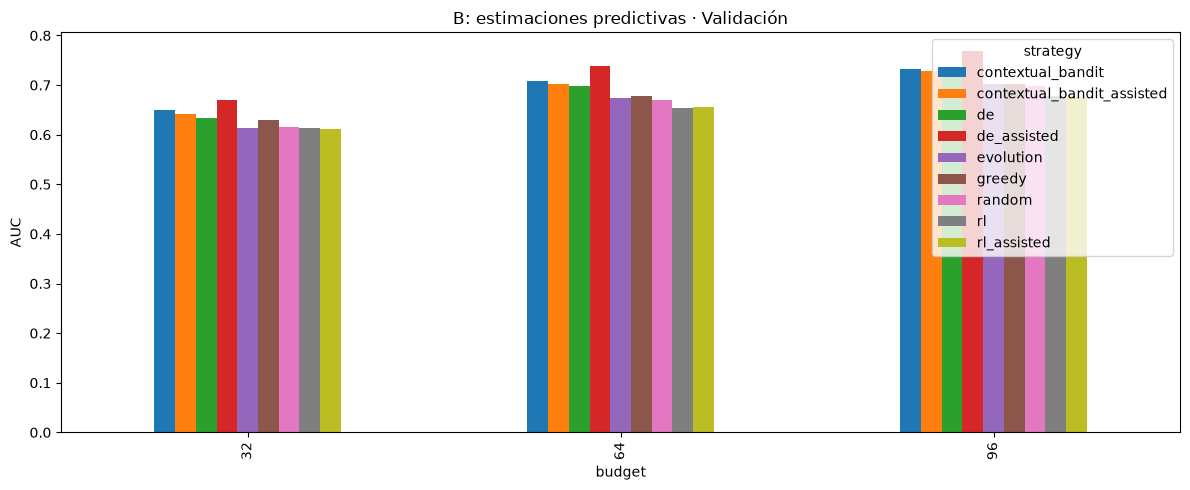

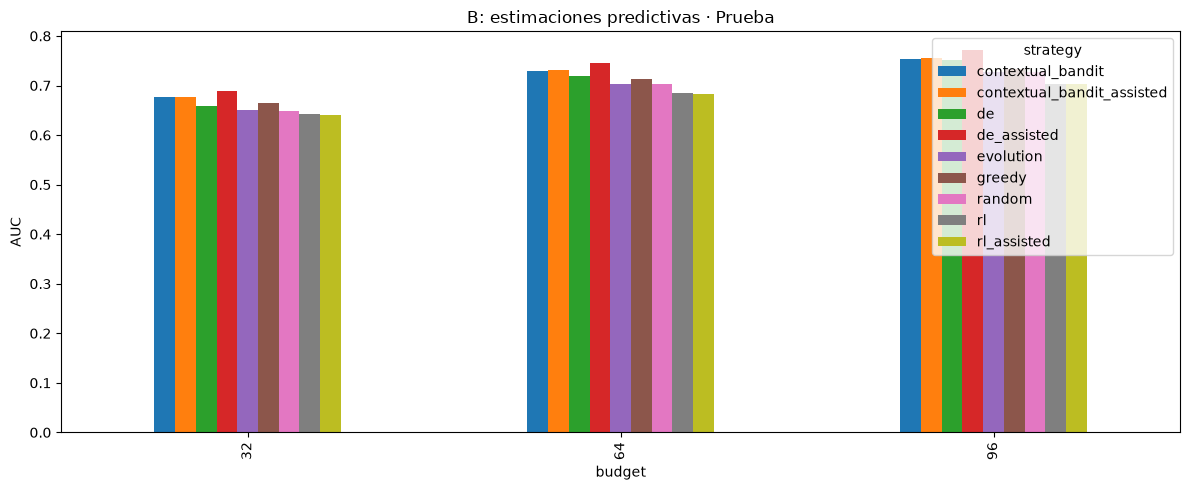

In [4]:
generative = comparison.loc[comparison["experiment"].eq("B")]
display(generative)
for split, label in (("validation", "Validación"), ("test", "Prueba")):
    generative.loc[generative["split"].eq(split)].pivot(
        index="budget", columns="strategy", values="mean_auc"
    ).plot.bar(
        figsize=(12, 5), ylabel="AUC", title=f"B: estimaciones predictivas · {label}"
    )
    plt.tight_layout()
    plt.show()

## 4. Terminación y alcance

Se conservan episodios que agotan soporte o presupuesto. El alcance usa una referencia de entrenamiento congelada, no etiquetas finales para fijar el umbral. Las consultas que no alcanzan el objetivo siguen censuradas; no se sustituyen por éxitos.

In [5]:
display(pd.read_csv(REPORT_DIR / "termination_counts.csv"))
display(pd.read_csv(REPORT_DIR / "target_attainment.csv"))

,split,experiment,strategy,budget,termination,size
0,test,A,contextual_bandit,32,budget_exhausted,100
1,test,A,contextual_bandit,64,budget_exhausted,100
2,test,A,contextual_bandit,96,budget_exhausted,100
3,test,A,contextual_bandit_assisted,32,budget_exhausted,100
4,test,A,contextual_bandit_assisted,64,budget_exhausted,100
...,...,...,...,...,...,...
103,validation,B,rl,64,budget_exhausted,100
104,validation,B,rl,96,budget_exhausted,100
105,validation,B,rl_assisted,32,budget_exhausted,100
106,validation,B,rl_assisted,64,budget_exhausted,100


,split,experiment,strategy,budget,scenario,policy_seed,attained,queries_to_target,target_fraction,reference_hypervolume,target_reference_scope
0,validation,A,evolution,32,0,42,False,NaN,0.9,0.090339,training_only_frozen_before_test
1,validation,A,random,32,0,42,False,NaN,0.9,0.090339,training_only_frozen_before_test
2,validation,A,greedy,32,0,42,False,NaN,0.9,0.090339,training_only_frozen_before_test
3,validation,A,rl,32,0,42,False,NaN,0.9,0.090339,training_only_frozen_before_test
4,validation,A,rl,32,0,43,False,NaN,0.9,0.090339,training_only_frozen_before_test
...,...,...,...,...,...,...,...,...,...,...,...
5995,test,B,contextual_bandit_assisted,96,19,44,False,NaN,0.9,0.090339,training_only_frozen_before_test
5996,test,B,contextual_bandit_assisted,96,19,45,False,NaN,0.9,0.090339,training_only_frozen_before_test
5997,test,B,contextual_bandit_assisted,96,19,46,False,NaN,0.9,0.090339,training_only_frozen_before_test
5998,test,B,de,96,19,42,False,NaN,0.9,0.090339,training_only_frozen_before_test


## 5. Qué muestran las comparaciones y cuánto cuestan

Los mayores promedios descriptivos se informan por modo y presupuesto, junto con los contrastes pareados de prueba. Un intervalo que incluye cero no demuestra igualdad; los intervalos son exploratorios, sin corrección por comparaciones múltiples y condicionados a una sola trayectoria.

Se separa la inversión en entrenamiento de políticas del tiempo por búsqueda y del trabajo de generación, selección, evaluación y asistencia. La amortización compara solo los alcances declarados y excluye predictores compartidos y FEM. Una política más costosa de entrenar puede ser inferior a un control y eso constituye un resultado del estudio, no un motivo para reemplazar el protocolo después de observar prueba.

In [6]:
from truss_research.evaluacion.lectura_resultados import search_interpretation

display(pd.read_csv(REPORT_DIR / "policy_costs.csv"))
amortization = pd.read_csv(REPORT_DIR / "amortization.csv")
if amortization.empty:
    display(
        Markdown(
            "No hay comparaciones de amortización disponibles para estas estrategias."
        )
    )
else:
    display(amortization)


display(Markdown(search_interpretation(STUDY_DIR, REPORT_DIR, max(CONFIG.budgets))))

,policy,seed,learning_objective,training_generated,training_cheap_evaluations,training_member_predictions,training_cheap_member_predictions,validation_generated,validation_cheap_evaluations,validation_member_predictions,validation_cheap_member_predictions,wall_seconds,cpu_seconds,training_surrogate_evaluations,optimizer_updates,validation_surrogate_evaluations
0,contextual_bandit,42,immediate,1600000,0,150000,0,1075200,0,33600,0,4733.645101,4385.015625,57248,12251,38400
1,contextual_bandit,43,immediate,1600032,0,150000,0,1075200,0,33600,0,4749.333727,4397.234375,57272,12251,38400
2,contextual_bandit,44,immediate,1600032,0,150000,0,1075200,0,33600,0,3487.463255,3417.703125,57128,12251,38400
3,contextual_bandit,45,immediate,1600032,0,150000,0,1075200,0,33600,0,3506.031008,3423.593750,57144,12251,38400
4,contextual_bandit,46,immediate,1600032,0,150000,0,1075200,0,33600,0,3477.038227,3404.968750,57360,12251,38400
5,contextual_bandit_assisted,42,immediate,1600000,1521073,150000,1521073,1075200,1020410,33600,1020410,3839.737378,3766.062500,57248,12251,38400
6,contextual_bandit_assisted,43,immediate,1600032,1518707,150000,1518707,1075200,1014636,33600,1014636,3833.049859,3759.203125,57272,12251,38400
7,contextual_bandit_assisted,44,immediate,1600032,1509806,150000,1509806,1075200,1009034,33600,1009034,3833.831135,3752.906250,57128,12251,38400
8,contextual_bandit_assisted,45,immediate,1600032,1521676,150000,1521676,1075200,1021437,33600,1021437,3818.091822,3746.968750,57144,12251,38400
9,contextual_bandit_assisted,46,immediate,1600032,1520714,150000,1520714,1075200,1022291,33600,1022291,3558.427438,3507.093750,57360,12251,38400


,experiment,budget,policy,baseline,extra_policy_training_seconds,search_saving_seconds,searches_to_amortize,scope
0,A,32,rl,random,5055.107395,-0.074104,NaN,exploratory_policy_cost_only_shared_predictors...
1,A,32,rl_assisted,greedy,5561.029815,-0.000173,NaN,exploratory_policy_cost_only_shared_predictors...
2,A,32,contextual_bandit,random,3990.702263,-0.070557,NaN,exploratory_policy_cost_only_shared_predictors...
3,A,32,contextual_bandit_assisted,greedy,3776.627526,0.012338,306089.0,exploratory_policy_cost_only_shared_predictors...
4,A,64,rl,random,5055.107395,-0.170512,NaN,exploratory_policy_cost_only_shared_predictors...
5,A,64,rl_assisted,greedy,5561.029815,0.006619,840142.0,exploratory_policy_cost_only_shared_predictors...
6,A,64,contextual_bandit,random,3990.702263,-0.162395,NaN,exploratory_policy_cost_only_shared_predictors...
7,A,64,contextual_bandit_assisted,greedy,3776.627526,0.038995,96850.0,exploratory_policy_cost_only_shared_predictors...
8,A,96,rl,random,5055.107395,-0.275175,NaN,exploratory_policy_cost_only_shared_predictors...
9,A,96,rl_assisted,greedy,5561.029815,-0.037294,NaN,exploratory_policy_cost_only_shared_predictors...


Con presupuesto **96**, los mayores promedios descriptivos de AUC de prueba son:
- **A, recuperación histórica: de (0.7836)**.
- **B, entorno predictivo: de_assisted (0.7708)**.

Los contrastes congelados permiten precisar esta lectura:
- Modo A: rl − contextual_bandit: diferencia media **-0.0254**, intervalo exploratorio **[-0.0456, -0.0033]**, que queda completamente por debajo de cero.
- Modo A: rl − random: diferencia media **-0.0101**, intervalo exploratorio **[-0.0302, +0.0090]**, que incluye cero.
- Modo B: rl − contextual_bandit: diferencia media **-0.0507**, intervalo exploratorio **[-0.0775, -0.0257]**, que queda completamente por debajo de cero.
- Modo B: rl − random: diferencia media **-0.0247**, intervalo exploratorio **[-0.0439, -0.0049]**, que queda completamente por debajo de cero.

Una posición media menor no prueba equivalencia. Estos resultados describen las implementaciones y presupuestos evaluados; no descartan otros algoritmos RL o ajustes. Las consultas sin topología histórica, las proyecciones y los duplicados también condicionan el uso del presupuesto. B no aporta validación estructural independiente.

## 6. Curvas de calidad y frentes finales

Las curvas usan los episodios exportados y prolongan como meseta los episodios terminados. Los frentes muestran el escenario 0 y la semilla representativa al mayor presupuesto. Son diagnósticos de una ejecución, no intervalos poblacionales. A conserva respuestas registradas y B estimaciones; no se certifican diseños nuevos.

Los gráficos deben leerse junto con consultas sin cobertura, duplicados y distancias: una estrategia puede consumir el mismo presupuesto y recuperar menos diseños históricos distintos. La ventaja dentro de B puede no mantenerse en A, porque cambiar el evaluador cambia la evidencia disponible.

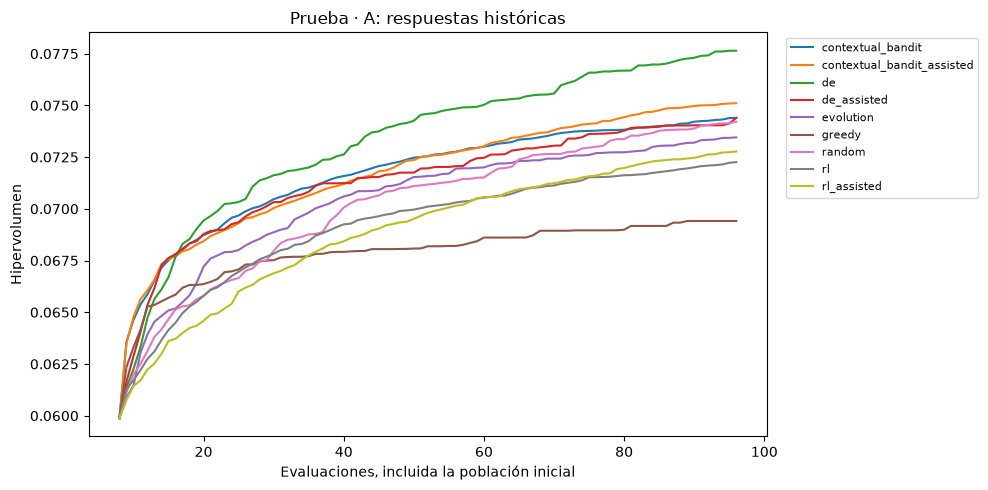

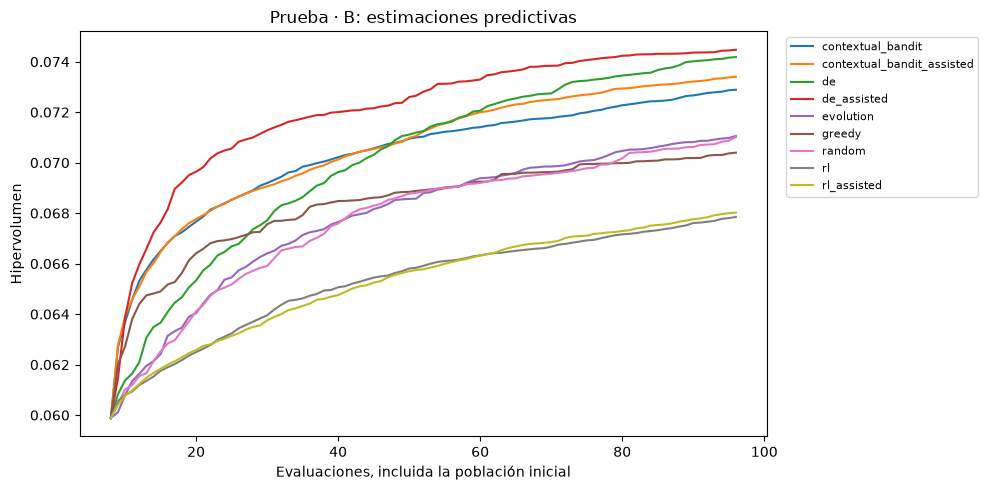

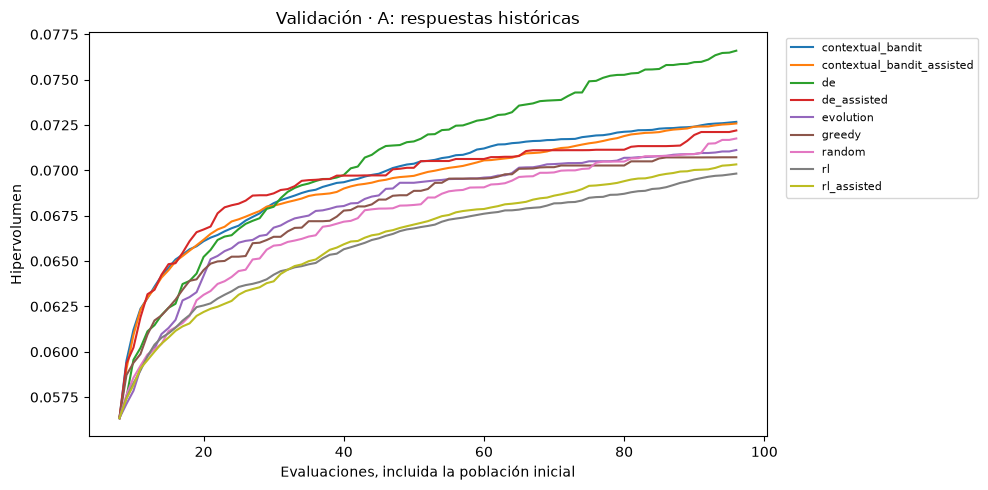

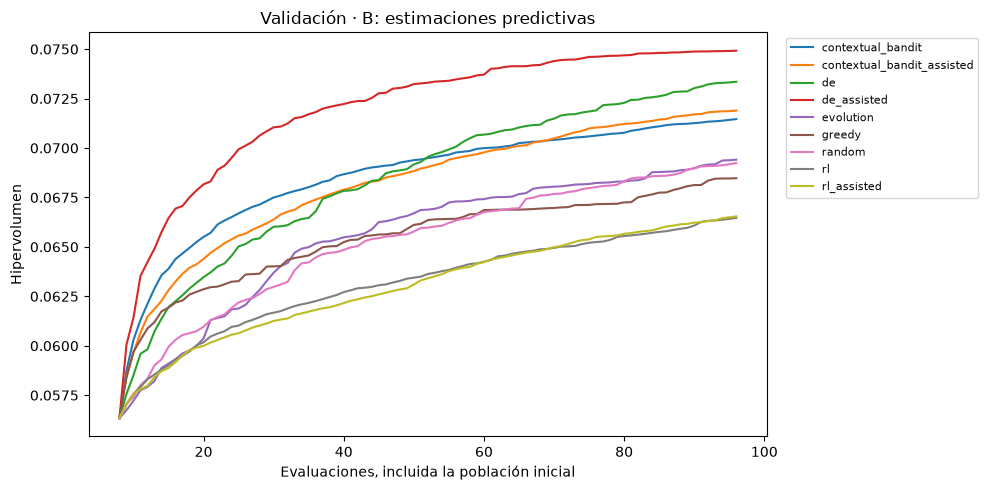

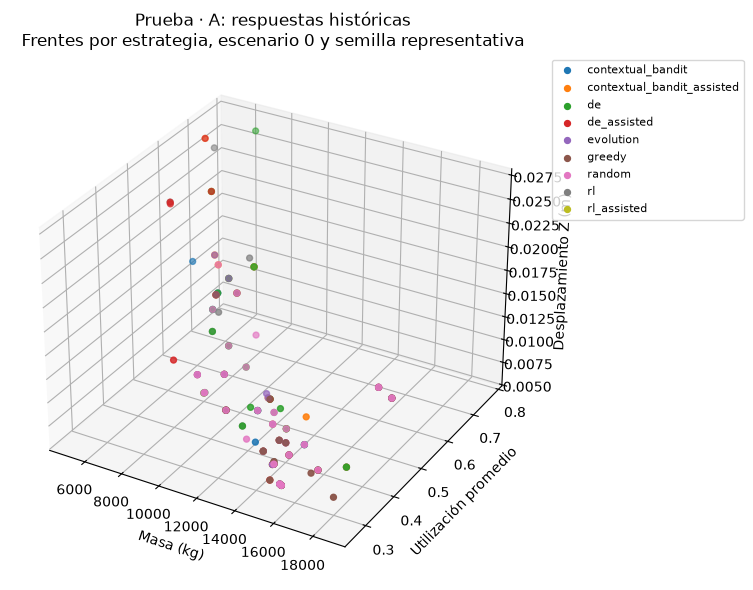

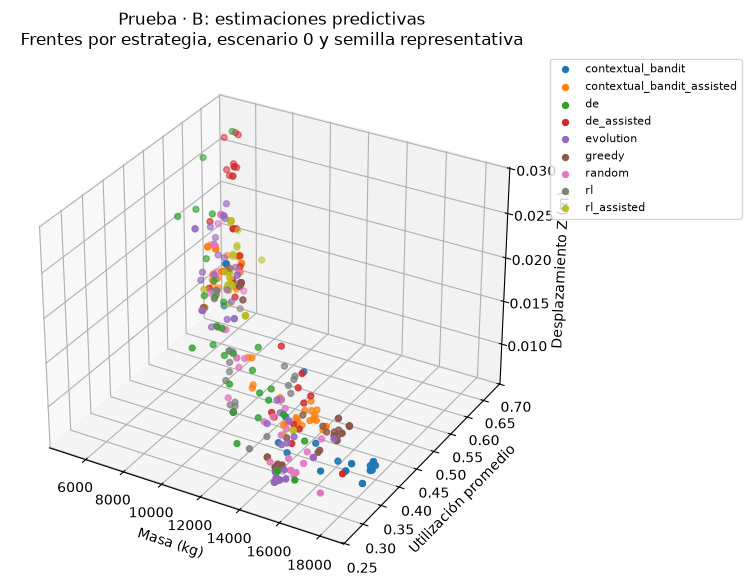

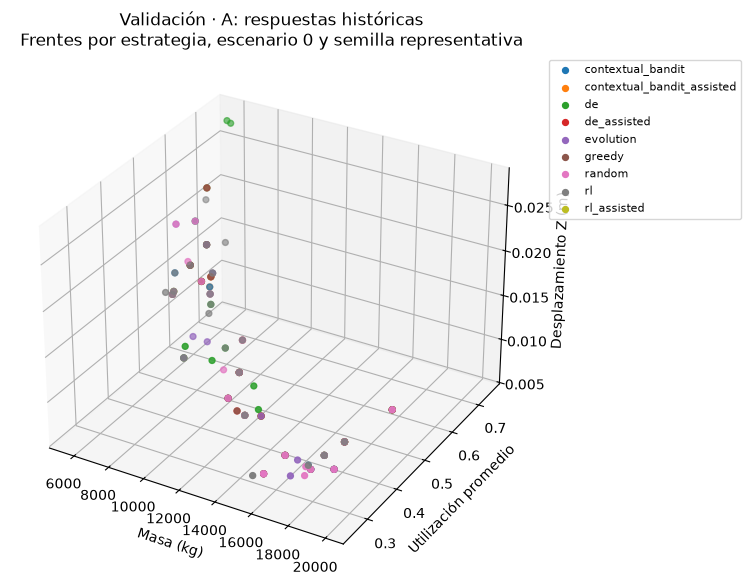

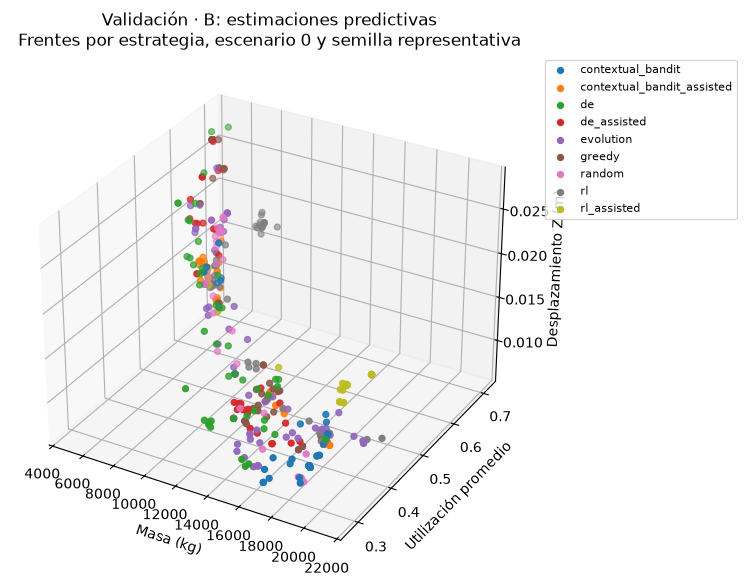

In [7]:
from truss_research.evaluacion.figuras import search_figures

for figure in search_figures(REPORT_DIR, max(CONFIG.budgets)):
    display(figure)
    plt.close(figure)